# TMC1 variant map — end-to-end reproduction

Rebuilds four artifacts from public sources only, with no dependency on the Claude Science connectors:

| output | contents |
|---|---|
| `tmc1_clinvar_variant_map.csv` | every ClinVar variant in *TMC1*, mapped to the MANE protein frame, with asserted conditions and structural distances |
| `tmc1_tm_enrichment.csv` | Fisher tests for transmembrane enrichment of pathogenic missense, under UniProt and cryo-EM helix definitions |
| `tmc1_pore_distance_sensitivity.csv` | permutation tests on distance-to-pore across five confidence filters |
| `tmc1_pore_distance.png` | the 3D pore map and the distance distributions |

**Sources** (all queried live over HTTPS)

1. **gnomAD GraphQL** (`gnomad.broadinstitute.org/api`) — ClinVar mirror for *TMC1* (clinical significance, review status, gold stars) and gnomAD r4 allele counts. The mirror is a dated snapshot; the notebook records `clinvar_release_date`.
2. **NCBI E-utilities** (`eutils.ncbi.nlm.nih.gov`) — live ClinVar `esummary` for asserted conditions and submission counts.
3. **Ensembl REST** (`rest.ensembl.org`) — CDS blocks, exons and CDS sequence of the MANE transcript ENST00000297784.
4. **UniProt REST** (`rest.uniprot.org`) — Q8TDI8 sequence and transmembrane/topological features.
5. **AlphaFold DB** (`alphafold.ebi.ac.uk`) — model AF-Q8TDI8-F1 v6 coordinates and PAE matrix.
6. **RCSB PDB** (`files.rcsb.org`) — 7USW, the expanded *C. elegans* TMC-1 complex at 3.1 Å.

**Two caveats on exact reproduction.** The gnomAD ClinVar mirror and live ClinVar both advance over time: re-running months later will shift variant counts and some condition assertions. Permutation p-values are Monte-Carlo estimates; the seeds below reproduce the published numbers exactly, but only if the test calls run in the order given.

**Contact email.** NCBI asks for one. Set `NCBI_EMAIL` in your environment before running; the notebook omits the parameter if it is unset.

In [1]:
import os, sys, json, time, platform, urllib.request, urllib.parse
import numpy as np, pandas as pd, scipy, matplotlib, biotite
print('python     ', sys.version.split()[0], '|', platform.platform())
for m in (np, pd, scipy, matplotlib, biotite):
    print(f'{m.__name__:<12}', m.__version__)
print()
print('created with: conda create -n tmc1 python=3.11 biotite biopython matplotlib pandas scipy numpy')
WORKDIR = os.getcwd(); os.makedirs('struct', exist_ok=True)
NCBI_EMAIL = os.environ.get('NCBI_EMAIL')          # optional; see header
print('NCBI contact email set:', bool(NCBI_EMAIL))

python      3.11.8 | macOS-15.3.2-arm64-arm-64bit
numpy        2.4.6
pandas       2.3.3
scipy        1.17.1
matplotlib   3.11.2
biotite      1.6.0

created with: conda create -n tmc1 python=3.11 biotite biopython matplotlib pandas scipy numpy
NCBI contact email set: False


## 1. ClinVar records and gnomAD frequencies for *TMC1*

One GraphQL round-trip to gnomAD returns both the ClinVar mirror (845 rows at the 2026-09-28 snapshot) and every gnomAD r4 short variant in the gene, which supplies the allele frequencies. `clinvar_release_date` pins the snapshot.

In [2]:
GNOMAD_API = 'https://gnomad.broadinstitute.org/api'

def gql(query, timeout=300):
    req = urllib.request.Request(GNOMAD_API, json.dumps({'query': query}).encode(),
                                 {'Content-Type': 'application/json'})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        payload = json.loads(r.read())
    if 'errors' in payload:
        raise RuntimeError(payload['errors'])
    return payload['data']

release_date = gql('{ meta { clinvar_release_date } }')['meta']['clinvar_release_date']

QUERY = """{ gene(gene_symbol:"TMC1", reference_genome:GRCh38){
  gene_id
  clinvar_variants{ variant_id clinvar_variation_id clinical_significance gold_stars
                    review_status major_consequence pos transcript_id in_gnomad }
  variants(dataset:gnomad_r4){ variant_id exome{ac an} genome{ac an} } } }"""
gene = gql(QUERY)['gene']
clinvar_rows, gnomad_rows = gene['clinvar_variants'], gene['variants']
print(f'ClinVar mirror release {release_date}: {len(clinvar_rows)} variants; '
      f'gnomAD r4: {len(gnomad_rows)} variants in {gene["gene_id"]}')

# pooled exome+genome allele frequency per variant id
af = {}
for v in gnomad_rows:
    ac = an = 0
    for blk in ('exome', 'genome'):
        b = v.get(blk)
        if b and b.get('an'):
            ac += b.get('ac') or 0
            an += b['an']
    af[v['variant_id']] = (ac, an, ac / an if an else None)

ClinVar mirror release 2026-09-28: 845 variants; gnomAD r4: 4890 variants in ENSG00000165091


## 2. MANE transcript and UniProt reference

The protein frame is the MANE Select transcript ENST00000297784.10 / UniProt Q8TDI8. Three Ensembl calls give the CDS blocks (for the genomic→codon map), the exon blocks (to tell 3'UTR from intron for variants outside the CDS) and the spliced CDS sequence. UniProt supplies the canonical sequence plus the ten `TRANSMEM` and eleven `TOPO_DOM` features.

In [3]:
def rest_json(url, timeout=120):
    req = urllib.request.Request(url, headers={'Accept': 'application/json'})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return json.loads(r.read())

ENS = 'https://rest.ensembl.org'
TX, GENE_REGION = 'ENST00000297784', '9:72643000-72841000'

cds_feats = rest_json(f'{ENS}/overlap/region/human/{GENE_REGION}?feature=cds;content-type=application/json')
blocks = sorted({(f['start'], f['end']) for f in cds_feats if f.get('Parent') == TX})
exon_feats = rest_json(f'{ENS}/overlap/region/human/{GENE_REGION}?feature=exon;content-type=application/json')
exons = sorted({(f['start'], f['end']) for f in exon_feats if f.get('Parent') == TX})
cds = rest_json(f'{ENS}/sequence/id/{TX}?type=cds;content-type=application/json')['seq']
print(f'{len(blocks)} CDS blocks ({sum(b-a+1 for a,b in blocks)} bp), {len(exons)} exons, CDS {len(cds)} nt')

up = rest_json('https://rest.uniprot.org/uniprotkb/Q8TDI8.json')
PROT = up['sequence']['value']
TM, TOPO = [], []
for ft in up['features']:
    s, e = ft['location']['start']['value'], ft['location']['end']['value']
    if ft['type'] == 'Transmembrane':
        TM.append((s, e))
    elif ft['type'] == 'Topological domain':
        TOPO.append((s, e, ft['description']))
TM.sort(); TOPO.sort()
print(f'UniProt Q8TDI8: {len(PROT)} aa, {len(TM)} TM helices, {len(TOPO)} topological domains')

20 CDS blocks (2283 bp), 20 exons, CDS 2283 nt


UniProt Q8TDI8: 760 aa, 10 TM helices, 11 topological domains


## 3. Map every variant onto the protein frame

A genomic→CDS index is built from the CDS blocks (TMC1 is on the + strand). The CDS is translated and checked against the UniProt sequence — if that assertion fails, nothing downstream is trustworthy.

Consequences are then derived from the codon change rather than taken from the mirror: the mirror's `major_consequence` is not always the MANE call (four rows disagree, including two 3'UTR positions it labels missense). The mirror term is kept as a secondary column.

In [4]:
from textwrap import wrap

BASES, AAS = 'TCAG', 'FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG'
CODON = {b1+b2+b3: AAS[i] for i, (b1, b2, b3) in enumerate(
    (x, y, z) for x in BASES for y in BASES for z in BASES)}

g2c, k = {}, 0
for a, b in blocks:
    for g in range(a, b + 1):
        g2c[g] = k; k += 1
protein = ''.join(CODON[c] for c in wrap(cds, 3))
assert protein[:-1] == PROT and protein[-1] == '*', 'translated CDS does not match UniProt Q8TDI8'
print(f'CDS translation matches UniProt Q8TDI8 ({len(PROT)} aa + stop); {len(g2c)} CDS bases mapped')

CDS_MIN, CDS_MAX = min(g2c), max(g2c)

def off_cds_label(pos):
    """A variant outside the CDS: 3'UTR / 5'UTR if exonic, else intronic."""
    if not any(a <= pos <= b for a, b in exons):
        return 'intron_variant'
    return "3_prime_UTR_variant" if pos > CDS_MAX else "5_prime_UTR_variant"

rows = []
for v in clinvar_rows:
    chrom, pos, ref, alt = v['variant_id'].split('-'); pos = int(pos)
    r = dict(variant_id=v['variant_id'], clinvar_variation_id=v['clinvar_variation_id'],
             pos=pos, ref=ref, alt=alt, consequence_clinvar_mirror=v['major_consequence'],
             clinical_significance=v['clinical_significance'], review_status=v['review_status'],
             gold_stars=v['gold_stars'], in_gnomad=v['in_gnomad'])
    aa_pos = aa_ref = aa_alt = hgvs_p = csq = None
    if len(ref) == 1 and len(alt) == 1:
        vtype = 'SNV'
        if pos in g2c:
            i = g2c[pos]; cnum, off = divmod(i, 3)
            codon = cds[cnum*3:cnum*3+3]
            assert codon[off] == ref, f'reference base mismatch at {v["variant_id"]}'
            aa_pos = cnum + 1
            aa_ref, aa_alt = CODON[codon], CODON[codon[:off] + alt + codon[off+1:]]
            hgvs_p = f'p.{aa_ref}{aa_pos}{aa_alt}'
            if aa_pos == 761:   csq = 'stop_retained_variant' if aa_alt == '*' else 'stop_lost'
            elif aa_ref == aa_alt: csq = 'synonymous_variant'
            elif aa_alt == '*': csq = 'stop_gained'
            elif aa_ref == '*': csq = 'stop_lost'
            elif aa_pos == 1:   csq = 'start_lost'
            else:               csq = 'missense_variant'
    else:
        d = len(alt) - len(ref)
        vtype = 'insertion' if d > 0 else ('deletion' if d < 0 else 'MNV')
        if d % 3: vtype += ' (frameshift-length)'
        for g in range(pos, pos + max(len(ref), 1) + 1):
            if g in g2c:
                aa_pos = g2c[g] // 3 + 1; break
    source = 'derived from MANE codon' if csq else 'gnomAD ClinVar mirror'
    if csq is None:
        csq = v['major_consequence']
        if csq == 'missense_variant' and aa_pos is None:      # mirror term is off-transcript
            csq = off_cds_label(pos); source = 'derived: outside MANE CDS (mirror term off-transcript)'
    ac, an, freq = af.get(v['variant_id'], (None, None, None))
    r.update(variant_type=vtype, aa_pos=aa_pos, aa_ref=aa_ref, aa_alt=aa_alt, hgvs_p=hgvs_p,
             consequence_mane=csq, consequence_source=source,
             splice_region_flag=v['major_consequence'] == 'splice_region_variant',
             gnomad_ac=ac, gnomad_an=an, gnomad_af=freq)
    rows.append(r)

df = pd.DataFrame(rows)
changed = df[df.consequence_mane != df.consequence_clinvar_mirror]
print(f'{len(df)} variants; {df.aa_pos.notna().sum()} map to a residue; '
      f'{len(changed)} consequences differ from the mirror:')
print(changed[['variant_id', 'consequence_clinvar_mirror', 'consequence_mane', 'hgvs_p']].to_string(index=False))

CDS translation matches UniProt Q8TDI8 (760 aa + stop); 2283 CDS bases mapped
845 variants; 596 map to a residue; 9 consequences differ from the mirror:
    variant_id consequence_clinvar_mirror      consequence_mane  hgvs_p
9-72754788-C-T      splice_region_variant    synonymous_variant p.Y215Y
9-72805384-G-A      splice_region_variant    synonymous_variant p.E523E
9-72835955-A-T           missense_variant    synonymous_variant p.A755A
9-72835973-A-G           missense_variant stop_retained_variant p.*761*
9-72835974-T-A           missense_variant   3_prime_UTR_variant    None
9-72835988-G-A           missense_variant   3_prime_UTR_variant    None
9-72835999-G-C           missense_variant   3_prime_UTR_variant    None
9-72836024-G-A           missense_variant   3_prime_UTR_variant    None
9-72836066-C-T           missense_variant   3_prime_UTR_variant    None


### Regions and classification groups

Each residue is labelled with its UniProt TM helix or topological domain, and each variant with a coarse class group.

In [5]:
PLP = {'Pathogenic', 'Likely pathogenic', 'Pathogenic/Likely pathogenic'}
BLB = {'Benign', 'Likely benign', 'Benign/Likely benign'}

def class_group(sig):
    if sig in PLP: return 'P/LP'
    if sig in BLB: return 'B/LB'
    if sig == 'Uncertain significance': return 'VUS'
    if sig.startswith('Conflicting'): return 'Conflicting'
    return 'Other'

def region_of(p):
    if p is None or pd.isna(p): return None
    p = int(p)
    for i, (a, b) in enumerate(TM, 1):
        if a <= p <= b: return f'TM{i}'
    for a, b, name in TOPO:
        if a <= p <= b: return f'{name} {a}-{b}'
    return 'other'

df['class_group'] = df.clinical_significance.map(class_group)
df['region'] = [region_of(p) for p in df.aa_pos]
df['tm_helix'] = [r if isinstance(r, str) and r.startswith('TM') else None for r in df.region]
print(df.class_group.value_counts().to_string())

class_group
B/LB           346
VUS            267
P/LP           186
Conflicting     44
Other            2


## 4. Asserted conditions from live ClinVar

The gnomAD mirror carries no phenotype, so conditions come from NCBI `esummary` in batches of 50 variation IDs. A variant is called dominant-asserted when some submitter named DFNA36, recessive-asserted when some submitter named DFNB7/11 (ClinVar folds DFNB11 into "Autosomal recessive nonsyndromic hearing loss 7"), and *both asserted* when both appear — conditions are aggregated per variant, not per submission, so "both" means different submitters disagreed, not a dual-inheritance claim.

In [6]:
EUTILS = 'https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esummary.fcgi'
ids = [str(v['clinvar_variation_id']) for v in clinvar_rows]
summaries = {}
for i in range(0, len(ids), 50):
    params = {'db': 'clinvar', 'retmode': 'json', 'id': ','.join(ids[i:i+50])}
    if NCBI_EMAIL: params['email'] = NCBI_EMAIL
    with urllib.request.urlopen(EUTILS + '?' + urllib.parse.urlencode(params), timeout=120) as r:
        res = json.loads(r.read())['result']
    summaries.update({u: res[u] for u in res.get('uids', [])})
    time.sleep(0.4)                      # NCBI: <= 3 requests/s without an API key
print(f'fetched {len(summaries)}/{len(ids)} ClinVar summaries')

DOM = {'Autosomal dominant nonsyndromic hearing loss 36'}
REC = {'Autosomal recessive nonsyndromic hearing loss 7', 'Hearing loss, autosomal recessive'}
GENERIC = {'not provided', 'not specified', 'Inborn genetic diseases', 'TMC1-related disorder'}

def conditions_of(vid):
    rec = summaries.get(str(int(vid)))
    if not rec: return (None, None, None, None)
    germ = rec.get('germline_classification') or {}
    names = [t.get('trait_name') for t in (germ.get('trait_set') or []) if t.get('trait_name')]
    dom, rec_ = any(n in DOM for n in names), any(n in REC for n in names)
    label = ('both asserted' if dom and rec_ else 'DFNA36 (dominant)' if dom
             else 'DFNB7/11 (recessive)' if rec_ else 'unspecified / generic only')
    n_sub = len((rec.get('supporting_submissions') or {}).get('scv', []))
    return ('|'.join(names), label, '|'.join(n for n in names if n not in GENERIC), n_sub)

df[['conditions', 'inheritance_assertion', 'conditions_specific', 'n_submissions']] = \
    [conditions_of(v) for v in df.clinvar_variation_id]
print(df.inheritance_assertion.value_counts().to_string())

fetched 845/845 ClinVar summaries
inheritance_assertion
unspecified / generic only    660
DFNB7/11 (recessive)          101
both asserted                  74
DFNA36 (dominant)              10


## 5. Structures: AlphaFold model and the *C. elegans* cryo-EM complex

Human TMC1 has no experimental structure, so the geometry comes from AF-Q8TDI8-F1 v6 placed in the frame of PDB 7USW chain A (*C. elegans* TMC-1, 3.1 Å) by structural superposition — sequence identity is in the twilight zone, so biotite's TM-align-style `superimpose_structural_homologs` is used rather than a sequence-anchored fit.

In [7]:
import biotite.structure as struc
import biotite.structure.io.pdb as pdbio, biotite.structure.io.pdbx as pdbx

def fetch(url, path):
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    return path

AF_PDB  = fetch('https://alphafold.ebi.ac.uk/files/AF-Q8TDI8-F1-model_v6.pdb', 'struct/AF-Q8TDI8-F1.pdb')
AF_PAE  = fetch('https://alphafold.ebi.ac.uk/files/AF-Q8TDI8-F1-predicted_aligned_error_v6.json', 'struct/AF-Q8TDI8-F1-pae.json')
CE_CIF  = fetch('https://files.rcsb.org/download/7USW.cif', 'struct/7usw.cif')

af = pdbio.PDBFile.read(AF_PDB).get_structure(model=1, extra_fields=['b_factor'])
af = af[struc.filter_amino_acids(af)]
plddt = np.array([af.b_factor[(af.res_id == i) & (af.atom_name == 'CA')][0] for i in range(1, len(PROT)+1)])
pae = np.array(json.load(open(AF_PAE))[0]['predicted_aligned_error'], dtype=float)

ce = pdbx.get_structure(pdbx.CIFFile.read(CE_CIF), model=1)
ce = ce[struc.filter_amino_acids(ce)]
ceA = ce[ce.chain_id == 'A']                       # chain A/B = TMC-1; C/E = CALM-1; D/F = TMIE-like
print(f'AlphaFold: {struc.get_residue_count(af)} residues, mean pLDDT {plddt.mean():.1f}, '
      f'{(plddt>=70).sum()} at pLDDT>=70 | 7USW chain A: {struc.get_residue_count(ceA)} residues')

fitted, _, fix_idx, mob_idx = struc.superimpose_structural_homologs(ceA, af, max_iterations=3)
print(f'TM-score {struc.tm_score(ceA, fitted, fix_idx, mob_idx):.3f} over {len(fix_idx)} CA pairs '
      f'(RMSD {struc.rmsd(ceA[fix_idx], fitted[mob_idx]):.2f} A)')
hu2ce = dict(zip(fitted.res_id[mob_idx].tolist(), ceA.res_id[fix_idx].tolist()))
ce2hu = {v: k for k, v in hu2ce.items()}

AlphaFold: 760 residues, mean pLDDT 76.9, 602 at pLDDT>=70 | 7USW chain A: 608 residues
TM-score 0.761 over 591 CA pairs (RMSD 7.54 A)


### Helix boundaries: UniProt vs the two structures

P-SEA secondary structure is annotated on both models and the *C. elegans* helices are mapped back to human numbering. Segments of ≥ 5 residues are kept, which is what reveals that TM1, TM4 and TM6 are each **two** helices with a short break — a detail an ≥ 8-residue threshold hides.

In [8]:
def helical_segments(atoms, min_len=5):
    sse = struc.annotate_sse(atoms)
    ids = [int(r) for r in struc.get_residues(atoms)[0]]
    segs, i = [], 0
    while i < len(ids):
        if sse[i] == 'a':
            j = i
            while j+1 < len(ids) and sse[j+1] == 'a' and ids[j+1] == ids[j]+1:
                j += 1
            if j-i+1 >= min_len: segs.append((ids[i], ids[j]))
            i = j+1
        else:
            i += 1
    return segs

af_segs = helical_segments(af)
ce_segs = helical_segments(ceA)

CE_TM = {}
for k, (a, b) in enumerate(TM, 1):
    mapped = [hu2ce[r] for r in range(a, b+1) if r in hu2ce]
    pieces = []
    for s, e in ce_segs:
        if mapped and min(max(mapped), e) >= max(min(mapped), s):
            hs = [ce2hu[c] for c in range(max(s, min(mapped)-6), min(e, max(mapped)+6)+1) if c in ce2hu]
            if len(hs) >= 5: pieces.append((min(hs), max(hs)))
    CE_TM[f'TM{k}'] = pieces

topo_rows = []
for k, (a, b) in enumerate(TM, 1):
    afh = [(s, e) for s, e in af_segs if min(b, e) >= max(a, s)]
    topo_rows.append(dict(TM=f'TM{k}', uniprot=f'{a}-{b}',
                          af_model_helix=' + '.join(f'{s}-{e}' for s, e in afh) or 'none',
                          cryoEM_helix_mapped=' + '.join(f'{s}-{e}' for s, e in CE_TM[f'TM{k}']) or 'none',
                          mean_plddt=round(float(plddt[a-1:b].mean()), 1)))
print(pd.DataFrame(topo_rows).to_string(index=False))

  TM uniprot    af_model_helix cryoEM_helix_mapped  mean_plddt
 TM1 183-220           183-208   186-206 + 211-220        90.6
 TM2 272-303           273-302             273-299        83.9
 TM3 360-390           357-395             359-389        84.8
 TM4 403-430 407-417 + 420-431   407-417 + 420-431        79.0
 TM5 435-469           434-493             435-472        80.8
 TM6 516-553 516-540 + 544-553   516-540 + 544-552        86.0
 TM7 573-593           573-590             573-589        88.0
 TM8 597-619           596-617             596-617        92.1
 TM9 634-657           632-655             634-656        87.0
TM10 701-734           700-759             702-736        79.6


## 6. The pore and its lining residues

TMC1 shares the TMEM16/OSCA fold, where the permeation path is a membrane-facing **groove between TM4 and TM6**, not an axial pore. So:

* the membrane normal is the mean of the ten TM helix axes (every helix lies within 9–30° of it);
* the **pore path** is the midline between the TM4 and TM6 helix axes, sampled at 40 heights along the shared span;
* **pore-lining residues** are those in TM4–TM7 (cryo-EM spans, kinks included) whose Cβ lies within 10 Å of that midline, whose side chain points toward it, and whose pLDDT ≥ 70.

The same rule is applied to all four helices; TM5 and TM7 contribute little because they pack behind TM4/TM6, which the per-helix table makes explicit.

In [9]:
from scipy.spatial import cKDTree

fit = fitted
caf = fit[fit.atom_name == 'CA']

def helix_axis_dir(a, b):
    P = caf.coord[(caf.res_id >= a) & (caf.res_id <= b)]
    d = np.linalg.svd(P - P.mean(0), full_matrices=False)[2][0]
    d /= np.linalg.norm(d)
    return (d if (P[-1]-P[0]) @ d > 0 else -d), P.mean(0)

dirs, cents = zip(*[helix_axis_dir(a, b) for a, b in TM])
ref = dirs[0]
normal = np.mean([d if d @ ref > 0 else -d for d in dirs], axis=0)
normal /= np.linalg.norm(normal)
center = np.mean(cents, axis=0)
print('TM helix tilt to the mean normal (deg):',
      np.round(np.degrees(np.arccos(np.clip(np.abs(np.array(dirs) @ normal), -1, 1))), 0))

def axis_samples(P, z, zs, w=4.0):
    out = []
    for zz in zs:
        wgt = np.exp(-((z - zz)**2) / (2*w**2)); wgt /= wgt.sum()
        out.append((P * wgt[:, None]).sum(0))
    return np.array(out)

P4 = caf.coord[(caf.res_id >= 403) & (caf.res_id <= 430)]      # UniProt TM4 / TM6 spans for the axes
P6 = caf.coord[(caf.res_id >= 516) & (caf.res_id <= 553)]
z4, z6 = (P4 - center) @ normal, (P6 - center) @ normal
zs = np.linspace(max(z4.min(), z6.min()), min(z4.max(), z6.max()), 40)
pore_path = (axis_samples(P4, z4, zs) + axis_samples(P6, z6, zs)) / 2
axis_tree = cKDTree(pore_path)
print(f'pore path {np.linalg.norm(np.diff(pore_path, axis=0), axis=1).sum():.1f} A long; '
      f'TM4-TM6 axis separation {np.linalg.norm(axis_samples(P4,z4,zs)-axis_samples(P6,z6,zs),axis=1).min():.1f}'
      f'-{np.linalg.norm(axis_samples(P4,z4,zs)-axis_samples(P6,z6,zs),axis=1).max():.1f} A')

heavy = fit[fit.element != 'H']
res_ids = np.unique(heavy.res_id)
CA_, CB_ = {}, {}
for r in res_ids:
    sub = heavy[heavy.res_id == r]
    CA_[int(r)] = sub.coord[sub.atom_name == 'CA'][0]
    m = sub.atom_name == 'CB'
    CB_[int(r)] = sub.coord[m][0] if m.any() else CA_[int(r)]

HULL = {h: (min(a for a, _ in CE_TM[h]), max(b for _, b in CE_TM[h])) for h in ('TM4','TM5','TM6','TM7')}
cand = []
for h, (a, b) in HULL.items():
    for r in range(a, b+1):
        d, i = axis_tree.query(CB_[r])
        cand.append(dict(helix=h, res=r, aa=PROT[r-1], d_cb_axis=round(float(d), 2),
                         facing=bool((CB_[r]-CA_[r]) @ (pore_path[i]-CA_[r]) > 0),
                         plddt=plddt[r-1]))
cand = pd.DataFrame(cand)
pore_lining = cand[(cand.d_cb_axis <= 10) & cand.facing & (cand.plddt >= 70)].copy()
pore_lining['label'] = [f'{a}{r}' for a, r in zip(pore_lining.aa, pore_lining.res)]

per_helix = pd.DataFrame([dict(
    helix=h, span=f'{a}-{b}', n_residues=b-a+1,
    n_facing=int(((cand.helix==h) & cand.facing & (cand.plddt>=70)).sum()),
    closest_facing=f"{cand[(cand.helix==h)&cand.facing].nsmallest(1,'d_cb_axis').aa.iloc[0]}"
                   f"{cand[(cand.helix==h)&cand.facing].nsmallest(1,'d_cb_axis').res.iloc[0]}",
    closest_dist=float(cand[(cand.helix==h)&cand.facing].d_cb_axis.min()),
    **{f'n_{c}': int(((cand.helix==h)&cand.facing&(cand.plddt>=70)&(cand.d_cb_axis<=c)).sum()) for c in (8,10,12)})
    for h, (a, b) in HULL.items()])
print(per_helix.to_string(index=False))
print('\npore-lining residues (n=%d):' % len(pore_lining))
print(pore_lining.groupby('helix').label.apply(' '.join).to_string())

TM helix tilt to the mean normal (deg): [13. 12. 20. 24.  9. 30. 14. 26. 13. 22.]
pore path 31.7 A long; TM4-TM6 axis separation 11.3-26.3 A
helix    span  n_residues  n_facing closest_facing  closest_dist  n_8  n_10  n_12
  TM4 407-431          25        13           N410          2.10    8     9    11
  TM5 435-472          38        18           F457         10.16    0     0     6
  TM6 516-552          37        12           T534          2.62    8     9    12
  TM7 573-589          17         6           A579          9.21    0     1     4

pore-lining residues (n=19):
helix
TM4    N407 M409 N410 M413 S414 M418 P421 T422 D425
TM6    Q522 R526 S530 L533 T534 V537 T538 I541 R546
TM7                                            A579


## 7. Per-residue distances, pLDDT and PAE

For every residue: the minimum heavy-atom distance to any pore-lining residue, the Cβ distance to the pore midline, and the median PAE between that residue and the pore-lining residues. PAE matters because pLDDT is local — a cytoplasmic residue can be confidently folded (high pLDDT) while its position *relative to the TM domain* is undetermined, which makes its distance-to-pore meaningless.

In [10]:
pore_res = pore_lining.res.tolist()
pore_atom_tree = cKDTree(heavy[np.isin(heavy.res_id, pore_res)].coord)
pore_idx = [r-1 for r in pore_res]
tm_cryoem = {r for pieces in CE_TM.values() for a, b in pieces for r in range(a, b+1)}

per_res = pd.DataFrame([dict(
    res=int(r), aa=PROT[int(r)-1], plddt=float(plddt[int(r)-1]), in_TM_cryoEM=int(r) in tm_cryoem,
    min_dist_to_pore=round(float(pore_atom_tree.query(heavy[heavy.res_id == r].coord)[0].min()), 2),
    cb_dist_to_axis=round(float(axis_tree.query(CB_[int(r)])[0]), 2),
    is_pore_lining=int(r) in pore_res,
    pae_to_pore_median=round(float(np.median(np.minimum(pae[int(r)-1, pore_idx], pae[pore_idx, int(r)-1]))), 2))
    for r in res_ids])

for col, src in [('plddt','plddt'), ('min_dist_to_pore','min_dist_to_pore'),
                 ('cb_dist_to_pore_axis','cb_dist_to_axis'), ('is_pore_lining','is_pore_lining'),
                 ('pae_to_pore_median','pae_to_pore_median'), ('in_TM_cryoEM','in_TM_cryoEM')]:
    lut = dict(zip(per_res.res, per_res[src]))
    df[col] = [lut.get(int(p)) if pd.notna(p) else None for p in df.aa_pos]

def ce_helix_of(p):
    if pd.isna(p): return None
    for h, pieces in CE_TM.items():
        for a, b in pieces:
            if a <= int(p) <= b: return h
    return None
df['tm_helix_cryoEM'] = [ce_helix_of(p) for p in df.aa_pos]
print(per_res.groupby('in_TM_cryoEM').pae_to_pore_median.describe()[['count','50%','75%','max']].round(1).to_string())

              count   50%   75%   max
in_TM_cryoEM                         
False         479.0  10.0  20.5  29.0
True          281.0   5.0   6.0  15.0


## 8. Output 1 — `tmc1_clinvar_variant_map.csv`

In [11]:
COLS = ['variant_id','clinvar_variation_id','pos','ref','alt','variant_type','consequence_mane',
        'splice_region_flag','consequence_clinvar_mirror','consequence_source','aa_pos','aa_ref','aa_alt',
        'hgvs_p','region','tm_helix','tm_helix_cryoEM','plddt','pae_to_pore_median','in_TM_cryoEM',
        'min_dist_to_pore','cb_dist_to_pore_axis','is_pore_lining','clinical_significance','class_group',
        'inheritance_assertion','conditions_specific','conditions','review_status','gold_stars',
        'n_submissions','in_gnomad','gnomad_ac','gnomad_an','gnomad_af']
df[COLS].sort_values(['pos','variant_id']).to_csv('tmc1_clinvar_variant_map.csv', index=False)  # variant_id breaks position ties deterministically
print(f'wrote tmc1_clinvar_variant_map.csv: {len(df)} rows x {len(COLS)} columns')

wrote tmc1_clinvar_variant_map.csv: 845 rows x 35 columns


## 9. Output 2 — `tmc1_tm_enrichment.csv`

Are pathogenic missense variants over-represented in the transmembrane helices? Fisher's exact test, run under both helix definitions (UniProt ranges, 304 aa; cryo-EM helices, 281 aa) and against two comparators: all other classified missense, and the benign set alone. The recessive-asserted subset is tested separately because dominant and recessive variants need not sit in the same place.

In [12]:
from scipy.stats import fisher_exact

missense = df[(df.consequence_mane == 'missense_variant') & df.aa_pos.notna()].copy()
out = []
for defname, col in [('UniProt TM ranges', 'tm_helix'),
                     ('cryo-EM helix boundaries (7USW-mapped)', 'tm_helix_cryoEM')]:
    missense['in_tm'] = missense[col].notna()
    plp = missense[missense.class_group == 'P/LP']
    non = missense[missense.class_group != 'P/LP']
    blb = missense[missense.class_group == 'B/LB']
    rec = plp[plp.inheritance_assertion == 'DFNB7/11 (recessive)']
    for name, A, B in [('P/LP vs all non-P/LP', plp, non), ('P/LP vs B/LB', plp, blb),
                       ('recessive P/LP vs all non-P/LP', rec, non)]:
        a, c = int(A.in_tm.sum()), int(B.in_tm.sum())
        orr, p = fisher_exact([[a, len(A)-a], [c, len(B)-c]])
        out.append(dict(tm_definition=defname, comparison=name, in_TM_group1=f'{a}/{len(A)}',
                        in_TM_group2=f'{c}/{len(B)}',
                        odds_ratio=round(float(orr), 2) if np.isfinite(orr) else 'inf',
                        p_fisher=round(float(p), 4)))
enrichment = pd.DataFrame(out)
enrichment.to_csv('tmc1_tm_enrichment.csv', index=False)
print(enrichment.to_string(index=False))

                         tm_definition                     comparison in_TM_group1 in_TM_group2 odds_ratio  p_fisher
                     UniProt TM ranges           P/LP vs all non-P/LP        25/48       99/271       1.89    0.0534
                     UniProt TM ranges                   P/LP vs B/LB        25/48          0/4        inf    0.1116
                     UniProt TM ranges recessive P/LP vs all non-P/LP        16/26       99/271       2.78    0.0190
cryo-EM helix boundaries (7USW-mapped)           P/LP vs all non-P/LP        23/48       91/271       1.82    0.0717
cryo-EM helix boundaries (7USW-mapped)                   P/LP vs B/LB        23/48          0/4        inf    0.1204
cryo-EM helix boundaries (7USW-mapped) recessive P/LP vs all non-P/LP        17/26       91/271       3.74    0.0022


## 10. Output 3 — `tmc1_pore_distance_sensitivity.csv`

Do pathogenic missense variants sit closer to the pore? **Medians** are compared, not means: the distance distribution has a long right tail of cytoplasmic residues and a mean difference is driven by a handful of them.

The main comparison is pathogenic vs all other classified missense pooled, because only a few benign missense variants survive the confidence filters; pathogenic vs benign is reported as secondary and becomes untestable (n < 2) at the stricter PAE cuts.

Filters: pLDDT ≥ 70 everywhere, plus — for residues outside the cryo-EM TM helices — a ceiling on median PAE to the pore residues. The table sweeps that ceiling, because the conclusion depends on it.

*The RNG is seeded once and the three headline tests run before the sweep; that call order is what reproduces the published p-values.*

In [13]:
rng = np.random.default_rng(7)

def permutation_median_test(A, B, nperm=20000):
    obs = np.median(A) - np.median(B)
    pool, nA = np.concatenate([A, B]), len(A)
    draws = np.array([(lambda s: np.median(s[:nA]) - np.median(s[nA:]))(rng.permutation(pool))
                      for _ in range(nperm)])
    return obs, (np.abs(draws) >= abs(obs)).mean()

missense['pass_plddt'] = missense.plddt >= 70
primary = missense[missense.pass_plddt & (missense.in_TM_cryoEM | (missense.pae_to_pore_median <= 10))]
A = primary[primary.class_group == 'P/LP'].min_dist_to_pore.values
C_ = primary[primary.class_group != 'P/LP'].min_dist_to_pore.values
B_ = primary[primary.class_group == 'B/LB'].min_dist_to_pore.values
R_ = primary[(primary.class_group == 'P/LP') &
             (primary.inheritance_assertion == 'DFNB7/11 (recessive)')].min_dist_to_pore.values
for nm, X, Y in [('P/LP vs all non-P/LP', A, C_), ('P/LP vs B/LB', A, B_),
                 ('recessive P/LP vs all non-P/LP', R_, C_)]:
    o, p = permutation_median_test(X, Y)
    print(f'{nm}: medians {np.median(X):.1f} vs {np.median(Y):.1f} A, diff {o:+.1f}, p={p:.4f}')

rows = []
for fname, mask in [('pLDDT ≥ 70 only', missense.pass_plddt)] + [
        (f'pLDDT ≥ 70 + PAE ≤ {c}', missense.pass_plddt &
         (missense.in_TM_cryoEM | (missense.pae_to_pore_median <= c))) for c in (15, 12, 10, 8)]:
    k = missense[mask]
    a = k[k.class_group == 'P/LP'].min_dist_to_pore.values
    c_ = k[k.class_group != 'P/LP'].min_dist_to_pore.values
    b_ = k[k.class_group == 'B/LB'].min_dist_to_pore.values
    o1, p1 = permutation_median_test(a, c_)
    o2, p2 = (permutation_median_test(a, b_) if len(b_) >= 2
              else (np.median(a) - np.median(b_) if len(b_) else np.nan, np.nan))
    rows.append(dict(filter=fname, n_PLP=len(a), n_nonPLP=len(c_), n_BLB=len(b_),
                     med_PLP=round(float(np.median(a)), 1), med_nonPLP=round(float(np.median(c_)), 1),
                     med_BLB=round(float(np.median(b_)), 1) if len(b_) else None,
                     diff_main=round(float(o1), 1), p_main=round(float(p1), 4),
                     diff_secondary=round(float(o2), 1) if np.isfinite(o2) else None,
                     p_secondary=(round(float(p2), 4) if np.isfinite(p2) else 'n/a (n<2)')))
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv('tmc1_pore_distance_sensitivity.csv', index=False)
print()
print(sensitivity.to_string(index=False))

P/LP vs all non-P/LP: medians 9.3 vs 12.1 A, diff -2.8, p=0.1085


P/LP vs B/LB: medians 9.3 vs 19.8 A, diff -10.5, p=0.1480


recessive P/LP vs all non-P/LP: medians 9.6 vs 12.1 A, diff -2.4, p=0.2503



               filter  n_PLP  n_nonPLP  n_BLB  med_PLP  med_nonPLP  med_BLB  diff_main  p_main  diff_secondary p_secondary
      pLDDT ≥ 70 only     48       223      3      9.6        16.7     26.3       -7.1  0.0062           -16.7      0.0267
pLDDT ≥ 70 + PAE ≤ 15     46       202      2      9.6        14.7     23.0       -5.1  0.0380           -13.4      0.0331
pLDDT ≥ 70 + PAE ≤ 12     45       189      2      9.6        13.3     23.0       -3.7  0.0894           -13.4      0.0232
pLDDT ≥ 70 + PAE ≤ 10     44       178      1      9.3        12.1     19.8       -2.8  0.1079           -10.5   n/a (n<2)
 pLDDT ≥ 70 + PAE ≤ 8     38       153      1      7.8        11.3     19.8       -3.6  0.0261           -12.0   n/a (n<2)


## 11. Output 4 — `tmc1_pore_distance.png`

Panel **a** places the variants in the structure: the Cα trace (pLDDT ≥ 70 segments), TM4 and TM6, the pore midline, the 19 pore-lining residues and the pathogenic/benign missense variants that survive filtering, viewed with the membrane normal vertical and cropped to the TM domain. Panel **b** shows the distance distributions with medians.

Styling here is plain matplotlib rcParams, so the figure is visually equivalent to the published artifact without depending on the house style helper.

Matplotlib is building the font cache; this may take a moment.


wrote tmc1_pore_distance.png


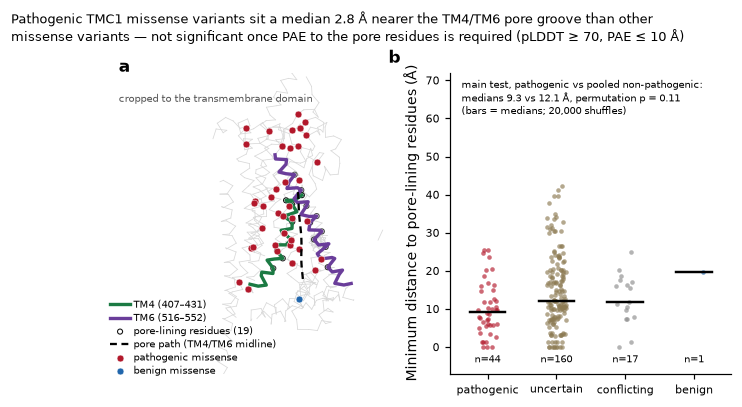

In [14]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9,
                     'axes.titlesize': 9, 'axes.labelsize': 9, 'legend.fontsize': 7,
                     'xtick.labelsize': 7, 'ytick.labelsize': 7, 'axes.spines.top': False,
                     'axes.spines.right': False, 'legend.frameon': False,
                     'xtick.direction': 'out', 'ytick.direction': 'out', 'pdf.fonttype': 42})
C_PLP, C_VUS, C_BLB, C_TM4, C_TM6 = '#b2182b', '#8c7a52', '#2166ac', '#1b7a43', '#6a3d9a'

e3 = normal
v = pore_path.mean(0) - center; v -= (v @ e3) * e3; e1 = v / np.linalg.norm(v); e2 = np.cross(e3, e1)
to_frame = lambda P: np.c_[(P-center) @ e1, (P-center) @ e2, (P-center) @ e3]
res_list = [int(r) for r in res_ids]
idx = {r: i for i, r in enumerate(res_list)}
CA_xyz = to_frame(np.array([CA_[r] for r in res_list]))
PORE_xyz = to_frame(pore_path)
tm_coords = CA_xyz[[idx[r] for r in [x for a, b in TM for x in range(a, b+1)]]]

fig = plt.figure(figsize=(7.4, 3.8))
gs = fig.add_gridspec(1, 2, width_ratios=[1.2, 1], wspace=0.04)
ax3 = fig.add_subplot(gs[0], projection='3d'); axd = fig.add_subplot(gs[1])
ax3.set_proj_type('ortho')
for i in range(len(CA_xyz)-1):
    if plddt[i] >= 70 and plddt[i+1] >= 70:
        ax3.plot(*zip(CA_xyz[i], CA_xyz[i+1]), color='#d8d8d8', lw=0.5, zorder=1)
for (a, b), col, lab in [(HULL['TM4'], C_TM4, f"TM4 ({HULL['TM4'][0]}–{HULL['TM4'][1]})"),
                         (HULL['TM6'], C_TM6, f"TM6 ({HULL['TM6'][0]}–{HULL['TM6'][1]})")]:
    P = CA_xyz[[idx[r] for r in range(a, b+1)]]
    ax3.plot(P[:,0], P[:,1], P[:,2], color=col, lw=2.2, zorder=4, label=lab)
P = CA_xyz[[idx[r] for r in pore_res]]
ax3.scatter(P[:,0], P[:,1], P[:,2], s=11, facecolors='none', edgecolors='#111', linewidths=0.7,
            zorder=5, label=f'pore-lining residues ({len(pore_res)})')
ax3.plot(PORE_xyz[:,0], PORE_xyz[:,1], PORE_xyz[:,2], color='black', lw=1.5, ls=(0,(3,2)),
         zorder=5, label='pore path (TM4/TM6 midline)')
for cls, col, lab in [('P/LP', C_PLP, 'pathogenic missense'), ('B/LB', C_BLB, 'benign missense')]:
    s = primary[primary.class_group == cls]
    if len(s):
        Q = CA_xyz[[idx[int(r)] for r in s.aa_pos]]
        ax3.scatter(Q[:,0], Q[:,1], Q[:,2], s=20, c=col, depthshade=False,
                    edgecolors='white', linewidths=0.3, zorder=6, label=lab)
mid = tm_coords.mean(0); half = (tm_coords.max(0)-tm_coords.min(0)).max()/2*1.02
for setter, m in zip((ax3.set_xlim, ax3.set_ylim, ax3.set_zlim), mid): setter(m-half, m+half)
ax3.set_box_aspect((1,1,1)); ax3.view_init(elev=4, azim=-38); ax3.set_axis_off()
ax3.legend(loc='lower left', bbox_to_anchor=(-0.05,-0.03), handletextpad=0.4, borderpad=0.2,
           labelspacing=0.3, fontsize=6.3)
ax3.text2D(0.0, 0.93, 'cropped to the transmembrane domain', transform=ax3.transAxes,
           fontsize=6.3, color='#555', va='top')
ax3.text2D(0.0, 0.99, 'a', transform=ax3.transAxes, fontweight='bold', fontsize=11, va='bottom')

groups = ['P/LP','VUS','Conflicting','B/LB']; names = ['pathogenic','uncertain','conflicting','benign']
jit = np.random.default_rng(1)
for i, (g, col) in enumerate(zip(groups, [C_PLP, C_VUS, '#8c8c8c', C_BLB])):
    vals = primary[primary.class_group == g].min_dist_to_pore.values
    axd.scatter(i + jit.uniform(-0.14, 0.14, len(vals)), vals, s=9, c=col, alpha=0.65, linewidths=0, zorder=2)
    axd.plot([i-0.26, i+0.26], [np.median(vals)]*2, color='black', lw=1.6, zorder=3)
    axd.text(i, -4.0, f'n={len(vals)}', ha='center', fontsize=6.5)
main = sensitivity[sensitivity['filter'] == 'pLDDT ≥ 70 + PAE ≤ 10'].iloc[0]
axd.set_xticks(range(4)); axd.set_xticklabels(names)
axd.set_ylabel('Minimum distance to pore-lining residues (Å)')
axd.set_ylim(-7, 72); axd.margins(x=0.08)
axd.annotate(f"main test, pathogenic vs pooled non-pathogenic:\n"
             f"medians {main.med_PLP} vs {main.med_nonPLP} Å, permutation p = {main.p_main:.2f}\n"
             f"(bars = medians; 20,000 shuffles)",
             xy=(0.04, 0.98), xycoords='axes fraction', fontsize=6.8, va='top')
axd.text(-0.22, 1.02, 'b', transform=axd.transAxes, fontweight='bold', fontsize=11, va='bottom')
fig.suptitle(f'Pathogenic TMC1 missense variants sit a median {abs(main.diff_main)} Å nearer the TM4/TM6 pore '
             f'groove than other\nmissense variants — not significant once PAE to the pore residues is required '
             f'(pLDDT ≥ 70, PAE ≤ 10 Å)', x=0.015, ha='left', fontsize=8.4)
fig.subplots_adjust(top=0.83)
fig.savefig('tmc1_pore_distance.png', bbox_inches='tight', dpi=300)
print('wrote tmc1_pore_distance.png')

## 12. Summary of what was written

In [15]:
for f in ['tmc1_clinvar_variant_map.csv', 'tmc1_tm_enrichment.csv',
          'tmc1_pore_distance_sensitivity.csv', 'tmc1_pore_distance.png']:
    print(f'{f:<42} {os.path.getsize(f):>9,} bytes')
print(f'\nClinVar mirror snapshot: {release_date} | {len(df)} variants | '
      f'{int((df.consequence_mane=="missense_variant").sum())} missense on the MANE frame')

tmc1_clinvar_variant_map.csv                 283,509 bytes
tmc1_tm_enrichment.csv                           513 bytes
tmc1_pore_distance_sensitivity.csv               465 bytes
tmc1_pore_distance.png                       272,271 bytes

ClinVar mirror snapshot: 2026-09-28 | 845 variants | 319 missense on the MANE frame
